In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Задача 1. Экспоненциальное распределение: ММ и ММП

Пусть $X_1,\ldots,X_n$ — независимая выборка из экспоненциального распределения

$$
X_i\sim\operatorname{Exp}(\lambda),\qquad \lambda>0,
$$

с плотностью

$$
f(x;\lambda)=\lambda e^{-\lambda x},\qquad x\ge0.
$$

Известно, что

$$
\mathbb E[X]=\frac1\lambda.
$$

1. Найдите оценку $\lambda$ методом моментов.
2. Найдите оценку $\lambda$ методом максимального правдоподобия.
3. Сравните полученные оценки.


**Решение**


## Пункт 1. Метод моментов

По методу моментов приравниваем теоретическое математическое ожидание к выборочному среднему:

$$
\frac1\lambda=\overline X.
$$

Отсюда

$$
\boxed{\widehat\lambda_{MM}=\frac1{\overline X}}.
$$


## Пункт 2. Метод максимального правдоподобия

Для независимой выборки

$$
L(\lambda)=\prod_{i=1}^n \lambda e^{-\lambda x_i}
=\lambda^n e^{-\lambda\sum_{i=1}^n x_i}.
$$

Логарифмируем:

$$
\ell(\lambda)=n\log\lambda-\lambda\sum_{i=1}^n x_i.
$$

Берём производную:

$$
\ell'(\lambda)=\frac n\lambda-\sum_{i=1}^n x_i.
$$

Приравниваем её к нулю:

$$
\frac n{\widehat\lambda}=\sum_{i=1}^n x_i.
$$

Поэтому

$$
\boxed{\widehat\lambda_{MLE}=\frac n{\sum_{i=1}^n X_i}=\frac1{\overline X}}.
$$

В этой модели методы дали одну и ту же оценку.


# Задача 2. Распределение Рэлея

Пусть $X_1,\ldots,X_n$ — независимая выборка из распределения Рэлея с плотностью

$$
f(x;\sigma)=\frac{x}{\sigma^2}\exp\!\left(-\frac{x^2}{2\sigma^2}\right),\qquad x\ge0,
$$

где $\sigma>0$ — неизвестный параметр.

Известно, что

$$
\mathbb E[X]=\sigma\sqrt{\frac\pi2}.
$$

1. Найдите оценку $\sigma$ методом моментов.
2. Найдите оценку $\sigma$ методом максимального правдоподобия.
3. Сравните полученные оценки.


***Решение***


## Пункт 1. Метод моментов

Приравниваем математическое ожидание к выборочному среднему:

$$
\sigma\sqrt{\frac\pi2}=\overline X.
$$

Поэтому

$$
\boxed{\widehat\sigma_{MM}=\overline X\sqrt{\frac2\pi}}.
$$


## Пункт 2. Метод максимального правдоподобия

Функция правдоподобия:

$$
L(\sigma)=\prod_{i=1}^n
\frac{x_i}{\sigma^2}
\exp\!\left(-\frac{x_i^2}{2\sigma^2}\right).
$$

Логарифмируем и оставляем слагаемые, зависящие от $\sigma$:

$$
\ell(\sigma)=-2n\log\sigma-rac1{2\sigma^2}\sum_{i=1}^n x_i^2+C.
$$

Производная:

$$
\ell'(\sigma)=-\frac{2n}{\sigma}+\frac1{\sigma^3}\sum_{i=1}^n x_i^2.
$$

Приравниваем к нулю:

$$
-2n\sigma^2+\sum_{i=1}^n x_i^2=0.
$$

Следовательно,

$$
\boxed{\widehat\sigma_{MLE}=\sqrt{\frac1{2n}\sum_{i=1}^n X_i^2}}.
$$

Оценки не совпадают: метод моментов использует $\overline X$, а ММП — сумму квадратов наблюдений.


# Задача 3. ММП и обучение линейной модели

Рассмотрим простую модель

$$
Y_i=\theta X_i+\varepsilon_i,
$$

где

$$
\varepsilon_i\sim\mathcal N(0,1)
$$

независимы.

Параметр $\theta$ неизвестен.

Получены следующие наблюдения:

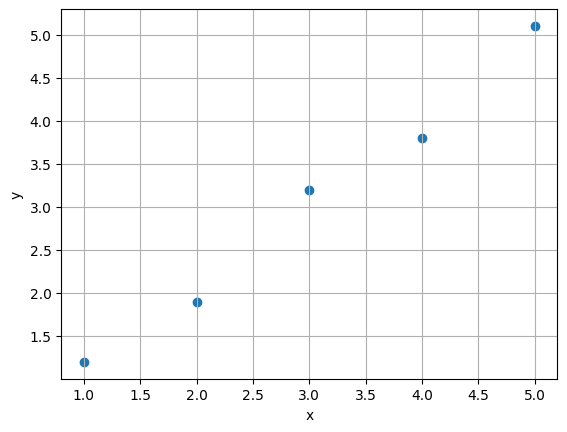

In [ ]:
x = np.array([1, 2, 3, 4, 5])
y = np.array([1.2, 1.9, 3.2, 3.8, 5.1])

plt.scatter(x, y)
plt.xlabel('x')
plt.ylabel('y')
plt.grid()
plt.show()

Для фиксированного $\theta$ модель предполагает

$$
Y_i\sim\mathcal N(\theta X_i,1).
$$

То есть разные значения $\theta$ задают разные модели.

Рассмотрим значения

$$
\theta\in[0,2].
$$

1. Для каждого $\theta$ вычисли логарифм правдоподобия наблюдаемых данных.

2. Найди значение $\theta$, при котором логарифм правдоподобия максимален.

3. Для тех же значений $\theta$ вычисли

$$
\operatorname{MSE}(\theta)
=
\frac1n\sum_{i=1}^n(y_i-\theta x_i)^2.
$$

4. Найди значение $\theta$, при котором MSE минимальна.

5. Сравни результаты.

Что общего между максимизацией правдоподобия и минимизацией MSE?

Так как

$$
Y_i\sim\mathcal N(\theta X_i,1),
$$

логарифм правдоподобия имеет вид

$$
\ell(\theta)
=
C-\frac12
\sum_{i=1}^n
(y_i-\theta x_i)^2,
$$

где $C$ не зависит от $\theta$.

Поэтому максимизация $\ell(\theta)$ эквивалентна минимизации

$$
\sum_{i=1}^n(y_i-\theta x_i)^2.
$$

In [ ]:
theta_grid = np.linspace(0, 2, 500)

log_likelihood = []
mse_values = []

for theta in theta_grid:
    y_pred = theta * x

    ll = -0.5 * np.sum((y - y_pred) ** 2)
    mse = np.mean((y - y_pred) ** 2)

    log_likelihood.append(ll)
    mse_values.append(mse)

log_likelihood = np.array(log_likelihood)
mse_values = np.array(mse_values)

theta_mle = theta_grid[np.argmax(log_likelihood)]
theta_mse = theta_grid[np.argmin(mse_values)]

print(f'MLE: {theta_mle:.3f}')
print(f'Minimum MSE: {theta_mse:.3f}')

MLE: 1.006
Minimum MSE: 1.006


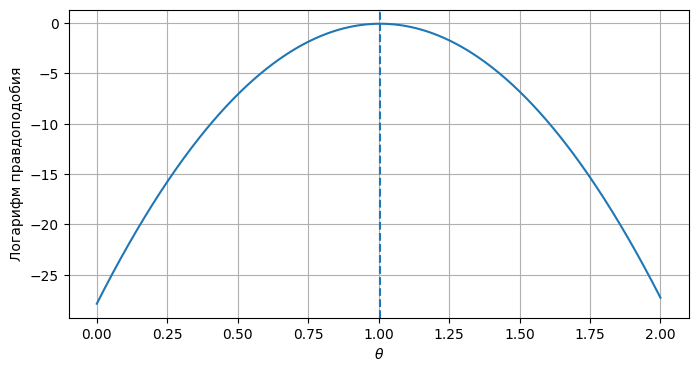

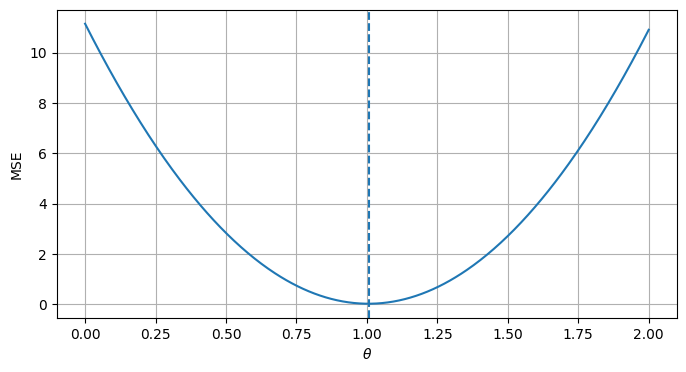

In [ ]:
plt.figure(figsize=(8, 4))

plt.plot(theta_grid, log_likelihood)
plt.axvline(theta_mle, linestyle='--')
plt.xlabel(r'$\theta$')
plt.ylabel('Логарифм правдоподобия')
plt.grid()
plt.show()

plt.figure(figsize=(8, 4))

plt.plot(theta_grid, mse_values)
plt.axvline(theta_mse, linestyle='--')
plt.xlabel(r'$\theta$')
plt.ylabel('MSE')
plt.grid()
plt.show()

Получилось одно и то же значение параметра:

$$
\widehat\theta_{\text{MLE}}
=
\arg\max_\theta \ell(\theta)
=
\arg\min_\theta
\sum_{i=1}^n(y_i-\theta x_i)^2.
$$

Это не совпадение.

Если ошибки модели считаются нормально распределёнными, то **максимизация правдоподобия эквивалентна минимизации суммы квадратов ошибок**.

Именно поэтому метод максимального правдоподобия напрямую связан с обучением моделей машинного обучения.

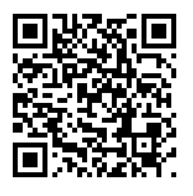

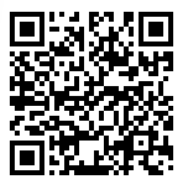